# Statistik-Labor Testat – NANUAG-Gesamtprojekt (Version 1)
**Wintersemester 2026/2027 – Gruppe 02**

***Hinweise:***
- Die Variablen unten sind bereits auf **Ihre Gruppe (02)** voreingestellt.
- Bitte überprüfen Sie Ihre Resultate laufend mit `Teilergebnisse_G02_V01.txt`.
- **Es wird dreimal abgegeben**, jeweils zusammen mit der zugehörigen Präsentation:
  Zwischenabgabe 1, Zwischenabgabe 2 und Endabgabe. Jede Abgabe besteht aus diesem (wachsenden)
  Notebook **und** einem PDF-Export davon, in Moodle.
  Dateiname je Abgabe: `Projekt_Gruppe02_<Nachnamen>_Zwischenabgabe1.ipynb`
  bzw. `..._Zwischenabgabe2.ipynb` bzw. `..._Endabgabe.ipynb`.
- Konkrete Wochentage/Uhrzeiten werden noch bekanntgegeben; siehe Terminplan für die Kalenderwochen.
- Geben Sie **niemals** die vollständige Tabelle mit 100.000 Zeilen aus — nutzen Sie `.head()`,
  `.sample()`, Aggregationen und Diagramme.
- Die vollständige Aufgabenstellung mit allen Teilaufgaben finden Sie in
  `Aufgabenstellung_Gruppe02.pdf`. Dieses Notebook ist das Arbeitsgerüst.

In [1]:
GRUPPENNUMMER = 2   # bereits auf Ihre Gruppe voreingestellt
VERSION = 1         # dieses Semester fuer alle Gruppen: Version 1

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

g = f"{GRUPPENNUMMER:02d}"
v = f"{VERSION:02d}"
pfad = "./"
print("Arbeite mit Dateien aus:", pfad)

Arbeite mit Dateien aus: ./


---
# Teil 1 – Personaldaten der NANUAG

## a) Daten einlesen

In [2]:
roh= pd.read_csv("nanuag_mitarbeiter_G02_V01.csv",sep=";")
#Anzahl Zeilen beim raw input
daten = roh.copy()
daten.head()
print(len(daten))
anzahl_start = len(daten)

100000


## b) Datenbereinigung
Dokumentieren Sie Ihre Regeln in einer Tabelle (z. B. als DataFrame).

In [3]:
#Zählen leerer Felder in der Tabelle
#print(daten.isna().sum())
#Ergebnis: 0 


#Leerstellen
#wandelt  Felder mit "", werden von isna nicht erkannt, in NaN umwandeln - NA = fehlender Wert, Ausdruck sucht nach "beliebig vielen Leerzeichen"
# "von Anfang Leerzeichen bis Ende Leerzeichen"
daten = daten.replace(r"^\s*$", pd.NA, regex=True)
leerstellen = daten.isna().any(axis=1)

print(leerstellen.sum(), "Zeilen, welche mind. ein leeres Feld haben")
#print(daten[leerstellen])

daten = daten[~leerstellen]


#Löschen Falscher Geburtsdatum Formate. Also z.B. Geburtstage als String eingegeben
daten["Geburtsdatum"] = pd.to_datetime(daten["Geburtsdatum"], format="%d.%m.%Y", errors="coerce") #Felder in Geburtsdatum mit einem falschen Format werden mit NaN markiert

fehler = daten["Geburtsdatum"].isna()

print(fehler.sum(), "Geburtsdaten welche nicht im Format Tag.Monat.Jahr sind")

#print(daten[fehler])
daten = daten.dropna(subset=["Geburtsdatum"]) #Zeilen wo es mit Nan markierte Felder gibt werden gelöscht

#Löschen von Geburtsdaten welche in der Zukunft liegen oder zu weit in der Vergangenheit
geburtstag_zukunft_vergangenheit = (daten["Geburtsdatum"] > pd.Timestamp.today()) | (daten["Geburtsdatum"] < pd.Timestamp("1900-01-01"))
#print(daten[geburtstag_zukunft_vergangenheit])

print(geburtstag_zukunft_vergangenheit.sum(), "Geburtsdaten welche über dem aktuellen Datum sind oder unter 01.01.1900 (Von Berechnung ausgenommen)")

#daten = daten[~geburtstag_zukunft_vergangenheit] #~ steht für Negation. Also alle Werte die True waren wurden False


#Löschen von Alterranges welche unter 16 und über 70 sind via "datetime" 
min_alter = 16
max_alter = 70
stichtag_jahr = 2026

geburtsjahr = daten["Geburtsdatum"].dt.year
unplausibel_alter = ((stichtag_jahr - geburtsjahr) < min_alter) | ((stichtag_jahr - geburtsjahr) > max_alter)

print(unplausibel_alter.sum(), "Personen unter", min_alter, "oder über", max_alter, "Jahre")

daten = daten[~unplausibel_alter]

#Löschen Doppelter Personalnummern
anzahl_dopplungen = daten["Personalnummer"].duplicated() #anzahl_dopplungen wird ein series aus True und False. True für alle dopellten Werte außer den ersten

print(anzahl_dopplungen.sum(), "Personalnummern, welche mehr als 1 Mal vorkommen") #ich zähle die anzahl der True Werte

daten = daten.drop_duplicates(subset="Personalnummer") #entfernt alle doppelten Felder außer das erste

#Prüfen ob Gehalt eine *Zahl* ist?
#print(daten["Jahresgehalt"].dtype)
#Ergebnis: float64 also Zahl


# Unplausible Gehälter (Rahmen: negative Zahlen oder 0)
unplausibles_gehalt = (daten["Jahresgehalt"]) <=  0

print(unplausibles_gehalt.sum(), "Jahresgehälter mit negativem Vorzeichen oder gleich 0")
#print(daten[unplausibles_gehalt])
unplausibles_gehalt = (daten["Jahresgehalt"]) <=  0

"""
print(unplausibles_gehalt.sum(), "Jahresgehälter mit negativem Vorzeichen oder gleich 0")
print((daten["Jahresgehalt"] == 0).sum(), "davon genau 0")      # NEU
print((daten["Jahresgehalt"] < 0).sum(), "davon negativ")       # NEU
#print(daten[unplausibles_gehalt])
"""

daten = daten[~unplausibles_gehalt]



#Prüfen ob die Namen Zeichen enthalten, welche nicht erlaubt sind
ungültig_vorname = ~daten["Vorname"].str.fullmatch(r"[A-Za-zÄÖÜäöüß\- ]+")
ungültig_nachname = ~daten["Nachname"].str.fullmatch(r"[A-Za-zÄÖÜäöüß\- ]+")
ungültig_namen = ungültig_nachname | ungültig_vorname

print("Es wurden", ungültig_namen.sum(), "Namen gefunden welche etwas anderes beinhalten außer A-Za-zÄÖÜäöüß -\n")
#print(daten[ungültig_namen][["Vorname", "Nachname"]])

vokale = "aeiouäöüAEIOUÄÖÜ"

# Nachname
kein_vokal_nachname    = ~daten["Nachname"].str.contains(f"[{vokale}]") #schaut ob mind. ein Vokal im namen ist
viele_konson_nachname  = daten["Nachname"].str.contains(f"[^{vokale}\\- ]{{5,}}") #erkennt wenn 5 aufeinanderfolgende Zeichen nicht aus den angegeben bestehen
zu_lang_nachname       = daten["Nachname"].str.len() > 25
gross_mitten_nachname  = daten["Nachname"].str.contains(r"[a-zäöüß][A-ZÄÖÜ]") #prüft ob nach einem vorgegebenen Kleinbuchstaben mit einem großen weitergemacht wird
nur_gross_nachname     = daten["Nachname"].str.fullmatch(r"[A-ZÄÖÜ\- ]{2,}") #prüft ob ein name ausschließlich aus Großbuchstaben, - und Leerzeichen besteht und mind. 2 Zeichen lang ist

# Vorname
kein_vokal_vorname     = ~daten["Vorname"].str.contains(f"[{vokale}]")
viele_konson_vorname   = daten["Vorname"].str.contains(f"[^{vokale}\\- ]{{5,}}")
zu_lang_vorname        = daten["Vorname"].str.len() > 25
gross_mitten_vorname   = daten["Vorname"].str.contains(r"[a-zäöüß][A-ZÄÖÜ]")
nur_gross_vorname      = daten["Vorname"].str.fullmatch(r"[A-ZÄÖÜ\- ]{2,}") 

falscher_name = (
    kein_vokal_nachname | viele_konson_nachname | zu_lang_nachname | gross_mitten_nachname | nur_gross_nachname |
    kein_vokal_vorname  | viele_konson_vorname  | zu_lang_vorname  | gross_mitten_vorname  | nur_gross_vorname
)

"""
print(falscher_name.sum(),"Falsche Namen nach folgenden Kriterien: kein Vokal\n" \
"Kleinbuchstabe und dann Großbuchstabe\n" \
"Nur Großbuchstaben, mind. 2 Zeichen lang\n" \
"Länger als 25 Zeichen\n" \
"Mehr als 5 Zeichen bestehen nicht aus Vokalen, - oder Leerstelle\n")
#print(daten[zufall][["Vorname", "Nachname"]])
regeln = {
    "ungültige Zeichen":      ungültig_namen,
    "kein Vokal":             kein_vokal_nachname | kein_vokal_vorname,
    "5+ Konsonanten":         viele_konson_nachname | viele_konson_vorname,
    "länger als 25":          zu_lang_nachname | zu_lang_vorname,
    "Groß mitten im Wort":    gross_mitten_nachname | gross_mitten_vorname,
    "nur Großbuchstaben":     nur_gross_nachname | nur_gross_vorname,
}

for regel, maske in regeln.items():
    print(f"\n{regel}: {maske.sum()} Zeilen")
    print(daten[maske][["Vorname", "Nachname"]].head(8).to_string(index=False))
"""   
daten = daten[~falscher_name]



#IQR auf Gehalt anwenden
gehalt_bereinigt = daten.copy()
gehalt_bereinigt = gehalt_bereinigt.sort_values("Jahresgehalt")
Q1 = gehalt_bereinigt["Jahresgehalt"].quantile(0.25)
Q3 = gehalt_bereinigt["Jahresgehalt"].quantile(0.75)
IQR = Q3 - Q1
untergrenze = Q1 - 1.5*IQR
obergrenze = Q3 + 1.5*IQR
gehalts_ausreißer = (gehalt_bereinigt["Jahresgehalt"] < untergrenze) | (gehalt_bereinigt["Jahresgehalt"] > obergrenze) 
gehalt_bereinigt = gehalt_bereinigt[~gehalts_ausreißer]
print(gehalts_ausreißer.sum(), "Ausreißer nach folgender Regel: [Q1 − 1,5 · IQR, Q3 + 1,5 · IQR]")

print(len(daten),"Daten übrig nach Bereinigung")


#WICHTIG: 103 + 95 aus den Gehaltsregeln entsprechen genau den Zeilen welche zur Musterlösung "zu viel" gelöscht wurden
#Gruppe 02: 98088 DS, Musterlösung: 98287, MIT IQR: 97501
#Nullwerte und negative Gehälter werden gelöscht, könnten aber auch behalten werden (198 und es sind 199 Unterschied)
#Die IQR Regel sollte diese aber sowieso auffangen


0 Zeilen, welche mind. ein leeres Feld haben
858 Geburtsdaten welche nicht im Format Tag.Monat.Jahr sind
286 Geburtsdaten welche über dem aktuellen Datum sind oder unter 01.01.1900 (Von Berechnung ausgenommen)
286 Personen unter 16 oder über 70 Jahre
284 Personalnummern, welche mehr als 1 Mal vorkommen
198 Jahresgehälter mit negativem Vorzeichen oder gleich 0
Es wurden 0 Namen gefunden welche etwas anderes beinhalten außer A-Za-zÄÖÜäöüß -

587 Ausreißer nach folgender Regel: [Q1 − 1,5 · IQR, Q3 + 1,5 · IQR]
98088 Daten übrig nach Bereinigung


In [4]:
#Protokolltabelle zur Datenbereinigung

protokoll = pd.DataFrame({
    "Regel (in dieser Reihenfolge angewendet)": [
        "Leeres Feld",
        "Geburtsdatum nicht im Format TT.MM.JJJJ",
        "Alter < 16 oder > 70 (zum 31.12.2026, inkl. Zukunftsdaten)",
        "Doppelte Personalnummer",
        "Jahresgehalt <= 0",
        "Ungültige Zeichen im Namen",
        "Zufallszeichenketten in Namen",
        "Gehaltsausreißer (IQR)"
    ],
    "Betroffene Datensätze": [
        leerstellen.sum(),
        fehler.sum(),
        unplausibel_alter.sum(),
        anzahl_dopplungen.sum(),
        unplausibles_gehalt.sum(),
        ungültig_namen.sum(),
        falscher_name.sum(),
        gehalts_ausreißer.sum()
    ]
})

#Output ohne Zeilennummern
print(protokoll.to_string(index=False))
print("Datensätze vorher:", anzahl_start, "| nachher:", len(gehalt_bereinigt))

                  Regel (in dieser Reihenfolge angewendet)  Betroffene Datensätze
                                               Leeres Feld                      0
                   Geburtsdatum nicht im Format TT.MM.JJJJ                    858
Alter < 16 oder > 70 (zum 31.12.2026, inkl. Zukunftsdaten)                    286
                                   Doppelte Personalnummer                    284
                                         Jahresgehalt <= 0                    198
                                Ungültige Zeichen im Namen                      0
                             Zufallszeichenketten in Namen                    286
                                    Gehaltsausreißer (IQR)                    587
Datensätze vorher: 100000 | nachher: 97501


## c) Alter bestimmen (Stichtag 31.12.2026)

In [5]:
#Rahmenbedingungen für Alter: 16-70 Jahre, Stichtag 2026
min_alter = 16
max_alter = 70
stichtag_jahr = 2026

#Logik zur Berechnung des Alters: Stichtagjahr - Geburtsjahr
daten["Alter"] = stichtag_jahr - daten["Geburtsdatum"].dt.year


#Überprüfung ob Bereinigung funktioniert hat
print(unplausibel_alter.sum(), "Personen unter", min_alter, "oder über", max_alter)


#Output
print("Jüngste Person:", daten["Alter"].min(), "Jahre")
print("Älteste Person:", daten["Alter"].max(), "Jahre")
print(daten[["Geburtsdatum", "Alter"]].head(10))
print("Durchschnittsalter gesamt:", round(daten["Alter"].mean(), 2), "Jahre")
print(daten.groupby("Anrede")["Alter"].mean().round(2))

286 Personen unter 16 oder über 70
Jüngste Person: 20 Jahre
Älteste Person: 68 Jahre
  Geburtsdatum  Alter
0   1999-03-20     27
1   1965-08-11     61
2   1998-02-18     28
3   2006-02-07     20
4   1965-04-04     61
5   1966-01-10     60
6   1984-09-28     42
7   1978-11-22     48
8   1961-07-03     65
9   1985-05-15     41
Durchschnittsalter gesamt: 44.01 Jahre
Anrede
Divers    43.95
Frau      44.10
Herr      43.93
Name: Alter, dtype: float64


## d) Explorative Analyse (Säulendiagramme, Tortendiagramme)

Altersklasse
≤20       1995
21–30    20029
31–40    19856
41–50    20100
>50      35521
Name: count, dtype: int64


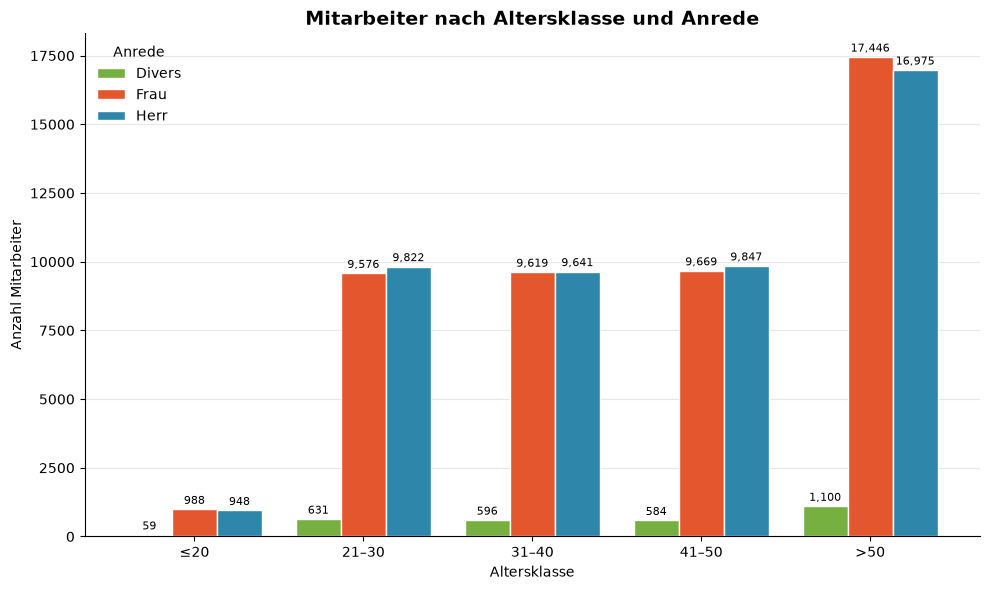

In [6]:
#Alter zum Stichtag 31.12.2026
#Daten zur Überprüfung des ersten Diagramms
#Funktionen wie fig, legend kommen aus der matplotlib
gehalt_bereinigt["Alter"] = 2026 - gehalt_bereinigt["Geburtsdatum"].dt.year


gehalt_bereinigt["Altersklasse"] = pd.cut(
    gehalt_bereinigt["Alter"],
    bins=[0, 20, 30, 40, 50, 200],
    labels=["≤20", "21–30", "31–40", "41–50", ">50"]
)

#print(gehalt_bereinigt[["Geburtsdatum", "Alter", "Altersklasse"]].head(10))
print(gehalt_bereinigt["Altersklasse"].value_counts().sort_index())

tabelle_alter = pd.crosstab(gehalt_bereinigt["Altersklasse"], gehalt_bereinigt["Anrede"])

farben = {"Frau": "#E4572E", "Herr": "#2E86AB", "Divers": "#76B041"}
farben_liste = [farben[spalte] for spalte in tabelle_alter.columns]

ax = tabelle_alter.plot(kind="bar", figsize=(10, 6), color=farben_liste, width=0.8, edgecolor="white")

# Zahlen über die Säulen schreiben
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}".format, fontsize=8, padding=2)

ax.set_title("Mitarbeiter nach Altersklasse und Anrede", fontsize=14, fontweight="bold")
ax.set_xlabel("Altersklasse")
ax.set_ylabel("Anzahl Mitarbeiter")
ax.tick_params(axis="x", rotation=0)

# Aufgeräumter Look: nur horizontale Hilfslinien, kein oberer/rechter Rahmen
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

ax.legend(title="Anrede", frameon=False)
plt.tight_layout()
plt.show()

Frau {'≤20': 988, '21–30': 9576, '31–40': 9619, '41–50': 9669, '>50': 17446}
Herr {'≤20': 948, '21–30': 9822, '31–40': 9641, '41–50': 9847, '>50': 16975}


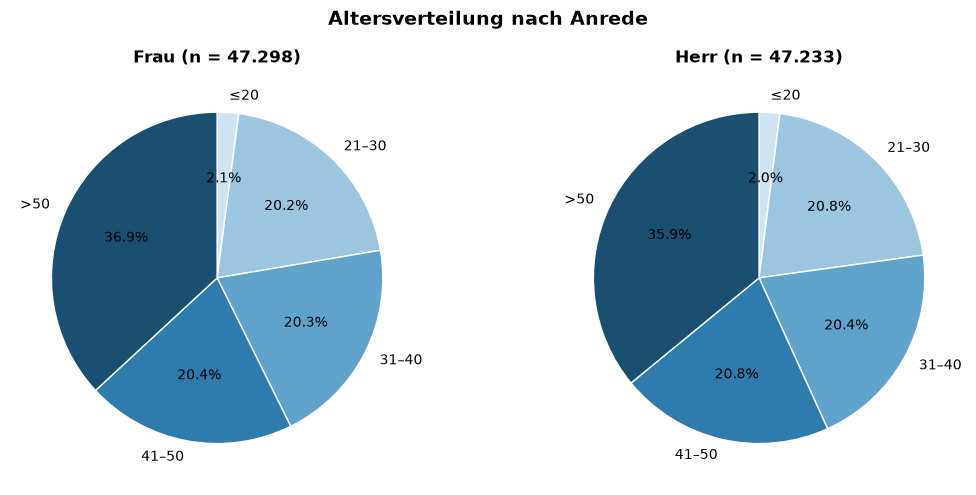

In [7]:
altersklassen = ["≤20", "21–30", "31–40", "41–50", ">50"]
farben_klassen = ["#CFE3F1", "#9CC5E0", "#5FA2CC", "#2E7BAE", "#1B4F72"]

fig, achsen = plt.subplots(1, 2, figsize=(11, 5))

for ax, anrede in zip(achsen, ["Frau", "Herr"]):
    teil = gehalt_bereinigt[gehalt_bereinigt["Anrede"] == anrede]
    anzahl = teil["Altersklasse"].value_counts().reindex(altersklassen)
    print(anrede, anzahl.to_dict())

    ax.pie(
        anzahl,
        labels=altersklassen,
        colors=farben_klassen,
        autopct="%1.1f%%",
        startangle=90,
        counterclock=False,
        wedgeprops={"edgecolor": "white"}
    )
    ax.set_title(f"{anrede} (n = {len(teil):,})".replace(",", "."), fontweight="bold")

fig.suptitle("Altersverteilung nach Anrede", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

Anrede                   Divers   Frau   Herr
Abteilung                                    
Finanzen                    251   3666   3826
Forschung & Entwicklung     242   3238   4024
IT                          295   3679   4655
Kundenservice               277   5195   4182
Logistik                    358   5772   5858
Personal                    174   3831   2887
Produktion                  903  14280  14219
Vertrieb                    470   7637   7582


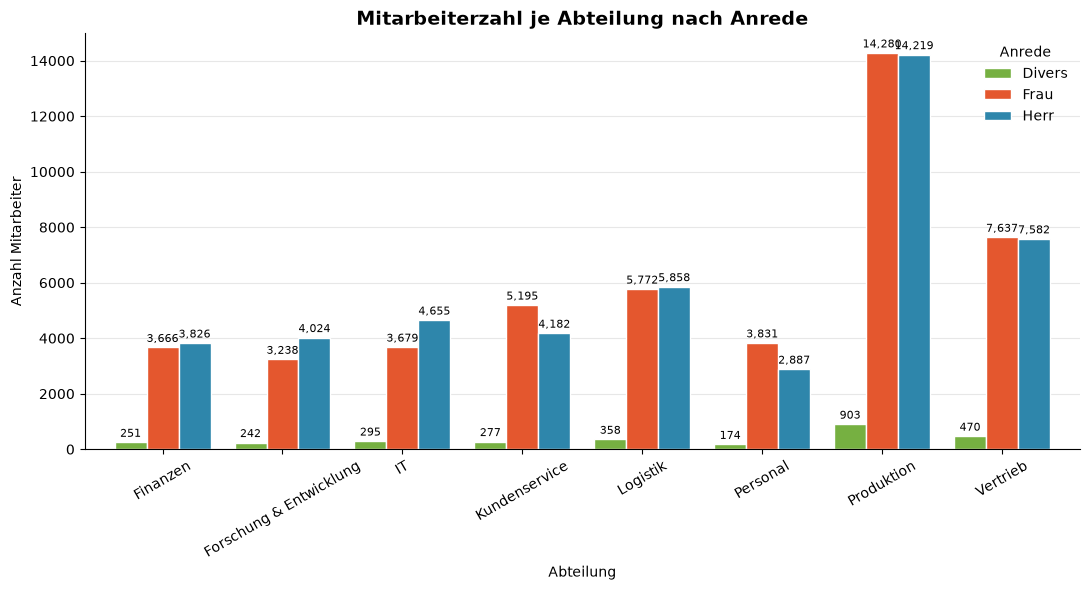

In [8]:
tabelle_abt = pd.crosstab(gehalt_bereinigt["Abteilung"], gehalt_bereinigt["Anrede"])
print(tabelle_abt)

farben = {"Frau": "#E4572E", "Herr": "#2E86AB", "Divers": "#76B041"}
farben_liste = [farben[spalte] for spalte in tabelle_abt.columns]

#ax = achsensystem
ax = tabelle_abt.plot(kind="bar", figsize=(11, 6), color=farben_liste, width=0.8, edgecolor="white")

for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}".format, fontsize=8, padding=2)

ax.set_title("Mitarbeiterzahl je Abteilung nach Anrede", fontsize=14, fontweight="bold")
ax.set_xlabel("Abteilung")
ax.set_ylabel("Anzahl Mitarbeiter")
ax.tick_params(axis="x", rotation=30)

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Anrede", frameon=False)

plt.tight_layout()
plt.show()

## e) Kennzahlen (Alter und Jahresgehalt, gesamt / Herr / Frau)

In [9]:
#Median Allgemein
median_alter = daten["Alter"].median()
#median_jahresgehalt = daten["Jahresgehalt"].median() #falls man nicht bereinigt möchte
median_jahresgehalt = gehalt_bereinigt["Jahresgehalt"].median()
print(f"Der allgemeine Median des Alters beträgt:{median_alter:.4f}")
print(f"Der allgemeine Median des Jahresgehalts beträgt:{median_jahresgehalt:.4f}\n")


#Median Jahresgehalt nach Anrede mit gehalt_bereinigt
#Divers
median_jahresgehalt_divers = gehalt_bereinigt.loc[daten["Anrede"] == "Divers", "Jahresgehalt"].median()
print(f"Der Median des Jahresgehaltes gefiltert nach Andrede 'Divers' beträgt: {median_jahresgehalt_divers:.4f}")
#Herr
median_jahresgehalt_herr = gehalt_bereinigt.loc[daten["Anrede"] == "Herr", "Jahresgehalt"].median()
print(f"Der Median des Jahresgehaltes gefiltert nach Andrede 'Herr' beträgt: {median_jahresgehalt_herr:.4f}")
#Frau
median_jahresgehalt_frau = gehalt_bereinigt.loc[daten["Anrede"] == "Frau", "Jahresgehalt"].median()
print(f"Der Median des Jahresgehaltes gefiltert nach Andrede 'Frau' beträgt: {median_jahresgehalt_frau:.4f}\n")

#Median Alter nach Anrede
#Divers
median_alter_divers = daten.loc[daten["Anrede"] == "Divers", "Alter"].median()
print(f"Der Median des Alters gefiltert nach Andrede 'Divers' beträgt: {median_alter_divers:.4f}")
#Herr
median_alter_herr = daten.loc[daten["Anrede"] == "Herr", "Alter"].median()
print(f"Der Median des Alters gefiltert nach Andrede 'Herr' beträgt: {median_alter_herr:.4f}")
#Frau
median_alter_frau = daten.loc[daten["Anrede"] == "Frau", "Alter"].median()
print(f"Der Median des Alters gefiltert nach Andrede 'Frau' beträgt: {median_alter_frau:.4f}\n")


#Durchschnitt Allgemein
durchschnitt_alter = daten["Alter"].mean()
durchschnitt_jahresgehalt = gehalt_bereinigt["Jahresgehalt"].mean()
print(f"Das durchschnittliche Alter beträgt: {durchschnitt_alter:.4f}")
print(f"Das durchschnittliche Jahresgehalt beträgt: {durchschnitt_jahresgehalt:.4f}\n")

#Durchschnitt Jahresgehalt nach Anrede
durchschnitt_jahresgehalt_divers = gehalt_bereinigt.loc[daten["Anrede"] == "Divers", "Jahresgehalt"].mean()
print(f"Der Durchschnitt des Jahresgehalts gefiltert nach Andrede 'Divers' beträgt: {durchschnitt_jahresgehalt_divers:.4f}")
#Herr
durchschnitt_jahresgehalt_herr = gehalt_bereinigt.loc[daten["Anrede"] == "Herr", "Jahresgehalt"].mean()
print(f"Der Durchschnitt des Jahresgehalts gefiltert nach Andrede 'Herr' beträgt: {durchschnitt_jahresgehalt_herr:.4f}")
#Frau
durchschnitt_jahresgehalt_frau = gehalt_bereinigt.loc[daten["Anrede"] == "Frau", "Jahresgehalt"].mean()
print(f"Der Durchschnitt des Jahresgehalts gefiltert nach Andrede 'Frau' beträgt: {durchschnitt_jahresgehalt_frau:.4f}\n")

#Durchschnitt Alter nach Anrede
#Divers
durchschnitt_alter_divers = daten.loc[daten["Anrede"] == "Divers", "Alter"].mean()
print(f"Der Durchschnitt des Alters gefiltert nach Andrede 'Divers' beträgt: {durchschnitt_alter_divers:.4f}")
#Herr
durchschnitt_alter_herr = daten.loc[daten["Anrede"] == "Herr", "Alter"].mean()
print(f"Der Durchschnitt des Alters gefiltert nach Andrede 'Herr' beträgt: {durchschnitt_alter_herr:.4f}")
#Frau
durchschnitt_alter_frau = daten.loc[daten["Anrede"] == "Frau", "Alter"].mean()
print(f"Der Durchschnitt des Alters gefiltert nach Andrede 'Frau' beträgt: {durchschnitt_alter_frau:.4f}\n")

#Empirische Varianz Allgemein
varianz_alter = daten["Alter"].var()
varianz_jahresgehalt = gehalt_bereinigt["Jahresgehalt"].var()
print(f"Die allgemeine empirische Varianz des Alters beträgt:{varianz_alter:.4f}")
print(f"Die allgemeine empirische Varianz des Jahresgehalts beträgt:{varianz_jahresgehalt:.4f}\n")

#Empirische Varianz des Jahresgehalts nach Anrede
#Divers
varianz_jahresgehalt_divers = gehalt_bereinigt.loc[daten["Anrede"] == "Divers", "Jahresgehalt"].var()
print(f"Die empirische Varianz des Jahresgehalts nach Anrede 'Divers' beträgt {varianz_jahresgehalt_divers:.4f}")
varianz_jahresgehalt_herr = gehalt_bereinigt.loc[daten["Anrede"] == "Herr", "Jahresgehalt"].var()
print(f"Die empirische Varianz des Jahresgehalts nach Anrede 'Herr' beträgt {varianz_jahresgehalt_herr:.4f}")
varianz_jahresgehalt_frau = gehalt_bereinigt.loc[daten["Anrede"] == "Frau", "Jahresgehalt"].var()
print(f"Die empirische Varianz des Jahresgehalts nach Anrede 'Frau' beträgt {varianz_jahresgehalt_frau:.4f}\n")

#Empirische Varianz des Alters nach Anrede
#Divers
varianz_alter_divers = daten.loc[daten["Anrede"] == "Divers", "Alter"].var()
print(f"Die empirische Varianz des Alters nach Anrede 'Divers' beträgt {varianz_alter_divers:.4f}")
varianz_alter_herr = daten.loc[daten["Anrede"] == "Herr", "Alter"].var()
print(f"Die empirische Varianz des Alters nach Anrede 'Herr' beträgt {varianz_alter_herr:.4f}")
varianz_alter_frau = daten.loc[daten["Anrede"] == "Frau", "Alter"].var()
print(f"Die empirische Varianz des Alters nach Anrede 'Frau' beträgt {varianz_alter_frau:.4f}\n")

#Empirische Standartabweichung Allgemein
stda_jahresgehalt = varianz_jahresgehalt ** 0.5
stda_alter = varianz_alter ** 0.5
print(f"Die empirische Standartabweichung des Alters beträgt {stda_alter:.4f}")
print(f"Die empirische Standartabweichung des Jahresgehalts beträgt {stda_jahresgehalt:.4f}\n")

#Empirische Standartabweichung des Gehalts nach Anrede
#Divers
stda_jahresgehalt_divers = varianz_jahresgehalt_divers ** 0.5
print(f"Die empirische Standartabweichung des Jahresgehalts nach Anrede 'Divers' beträgt {stda_jahresgehalt_divers:.4f}")
#Herr
stda_jahresgehalt_herr = varianz_jahresgehalt_herr ** 0.5
print(f"Die empirische Standartabweichung des Jahresgehalts nach Anrede 'Herr' beträgt {stda_jahresgehalt_herr:.4f}")
#Frau
stda_jahresgehalt_frau = varianz_jahresgehalt_frau ** 0.5
print(f"Die empirische Standartabweichung des Jahresgehalts nach Anrede 'Frau' beträgt {stda_jahresgehalt_frau:.4f}\n")

#Empirische Standartabweichung des Alters nach Anrede
#Divers
stda_alter_divers = varianz_alter_divers ** 0.5
print(f"Die empirische Standartabweichung des Alters nach Anrede 'Divers' beträgt {stda_alter_divers:.4f}")
#Herr
stda_alter_herr = varianz_alter_herr ** 0.5
print(f"Die empirische Standartabweichung des Alters nach Anrede 'Herr' beträgt {stda_alter_herr:.4f}")
#Frau
stda_alter_frau = varianz_alter_frau ** 0.5
print(f"Die empirische Standartabweichung des Alters nach Anrede 'Frau' beträgt {stda_alter_frau:.4f}\n")

#Spannweite Allgemein
spw_jahresgehalt = max(daten["Jahresgehalt"])-min(daten["Jahresgehalt"])
spw_alter = max(daten["Alter"])-min(daten["Alter"])
print(f"Die Allgemeine Spannweite des Jahresgehalts beträgt {spw_jahresgehalt:.4f}")
print(f"Die Allgemeine Spannweite des Alters beträgt {spw_alter:.4f}")

#Spannweite des Jahresgehalts nach Anrede
#Divers
spw_jahresgehalt_divers = max(gehalt_bereinigt[gehalt_bereinigt["Anrede"] == "Divers"]["Jahresgehalt"]) -min(gehalt_bereinigt[gehalt_bereinigt["Anrede"] == "Divers"]["Jahresgehalt"])
print(f"Die Spannweite des Jahresgehalts nach Anrede 'Divers' beträgt {spw_jahresgehalt_divers}")
#Herr
spw_jahresgehalt_herr = max(gehalt_bereinigt[gehalt_bereinigt["Anrede"] == "Herr"]["Jahresgehalt"]) -min(gehalt_bereinigt[gehalt_bereinigt["Anrede"] == "Herr"]["Jahresgehalt"])
print(f"Die Spannweite des Jahresgehalts nach Anrede 'Herr' beträgt {spw_jahresgehalt_herr}")
#Frau
spw_jahresgehalt_frau = max(gehalt_bereinigt[gehalt_bereinigt["Anrede"] == "Frau"]["Jahresgehalt"]) -min(gehalt_bereinigt[gehalt_bereinigt["Anrede"] == "Frau"]["Jahresgehalt"])
print(f"Die Spannweite des Jahresgehalts nach Anrede 'Frau' beträgt {spw_jahresgehalt_frau}")

#Spannweite des Alters nach Anrede
#Divers
spw_alter_divers = max(daten[daten["Anrede"] == "Divers" ]["Alter"]) - min(daten[daten["Anrede"] == "Divers" ]["Alter"])
print(f"Die Spannweite des alters nach Anrede 'Divers' beträgt {spw_jahresgehalt_divers}")
#Herr
spw_alter_herr = max(daten[daten["Anrede"] == "Herr" ]["Alter"]) - min(daten[daten["Anrede"] == "Herr" ]["Alter"])
print(f"Die Spannweite des alters nach Anrede 'Herr' beträgt {spw_jahresgehalt_herr}")
#Frau
spw_alter_frau = max(daten[daten["Anrede"] == "Frau" ]["Alter"]) - min(daten[daten["Anrede"] == "Frau" ]["Alter"])
print(f"Die Spannweite des alters nach Anrede 'Frau' beträgt {spw_jahresgehalt_frau}")



Der allgemeine Median des Alters beträgt:44.0000
Der allgemeine Median des Jahresgehalts beträgt:48586.0600

Der Median des Jahresgehaltes gefiltert nach Andrede 'Divers' beträgt: 49582.7150
Der Median des Jahresgehaltes gefiltert nach Andrede 'Herr' beträgt: 49631.5600
Der Median des Jahresgehaltes gefiltert nach Andrede 'Frau' beträgt: 47622.1300

Der Median des Alters gefiltert nach Andrede 'Divers' beträgt: 44.0000
Der Median des Alters gefiltert nach Andrede 'Herr' beträgt: 44.0000
Der Median des Alters gefiltert nach Andrede 'Frau' beträgt: 44.0000

Das durchschnittliche Alter beträgt: 44.0144
Das durchschnittliche Jahresgehalt beträgt: 49134.9983

Der Durchschnitt des Jahresgehalts gefiltert nach Andrede 'Divers' beträgt: 50091.9723
Der Durchschnitt des Jahresgehalts gefiltert nach Andrede 'Herr' beträgt: 50101.1603
Der Durchschnitt des Jahresgehalts gefiltert nach Andrede 'Frau' beträgt: 48110.0724

Der Durchschnitt des Alters gefiltert nach Andrede 'Divers' beträgt: 43.9492
De

## f) Zusammenhangsanalyse: Pearson- und Spearman-Korrelation Alter/Jahresgehalt

Die Pearson-Korrelation mit dem nicht bereinigten Jahresgehalt beträgt 0.1909
Die Spearman-Korrelation mit dem nicht bereinigten Jahresgehalt beträgt 0.6347
Die Pearson-Korrelation mit dem bereinigten Jahresgehalt beträgt 0.6157
Die Spearman-Korrelation mit dem bereinigten Jahresgehalt beträgt 0.6316


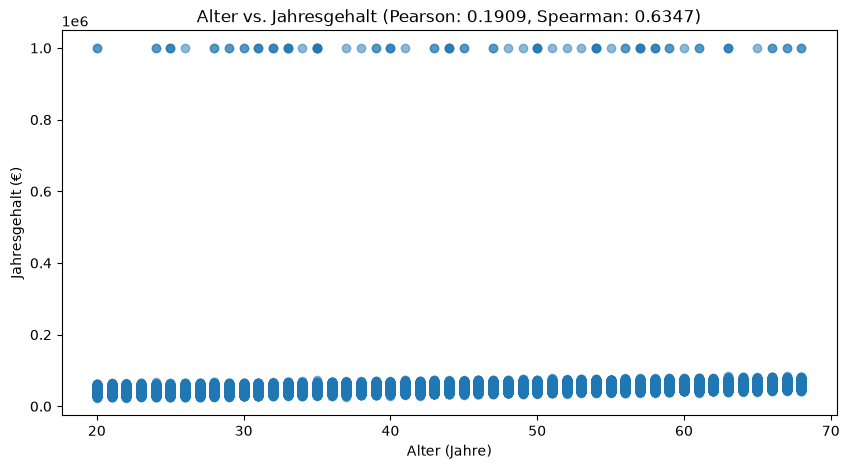

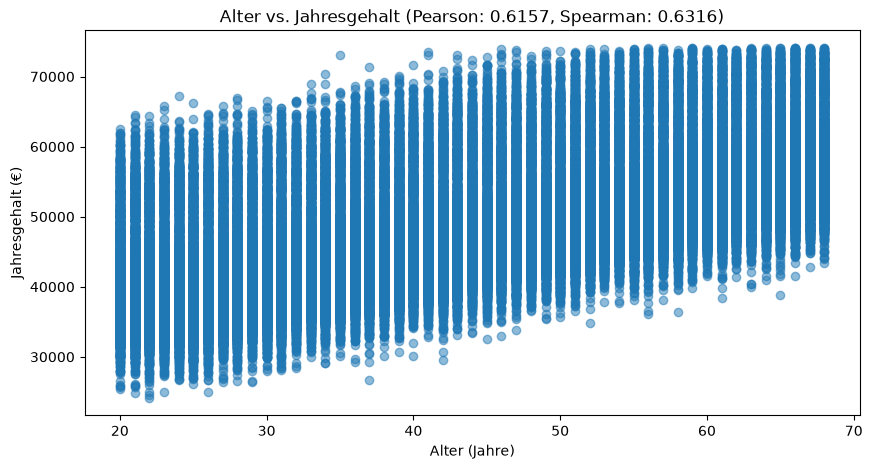

In [10]:
#Jahresgehalt nicht bereinigt

#Pearson-Korrelation (linear, metrische Daten)
pearson_korrelation = daten["Alter"].corr(daten["Jahresgehalt"], method='pearson')
print(f"Die Pearson-Korrelation mit dem nicht bereinigten Jahresgehalt beträgt {pearson_korrelation:.4f}")

#Spearman-Korrelation (monoton, Ränge / nicht-linear)
spearman_korrelation = daten["Alter"].corr(daten["Jahresgehalt"], method='spearman')
print(f"Die Spearman-Korrelation mit dem nicht bereinigten Jahresgehalt beträgt {spearman_korrelation:.4f}")


#Jahresgehalt bereinigt
pearson_korrelation_bereinigt = gehalt_bereinigt["Alter"].corr(gehalt_bereinigt["Jahresgehalt"], method='pearson')
print(f"Die Pearson-Korrelation mit dem bereinigten Jahresgehalt beträgt {pearson_korrelation_bereinigt:.4f}")

#Spearman-Korrelation (monoton, Ränge / nicht-linear)
spearman_korrelation_bereinigt = gehalt_bereinigt["Alter"].corr(gehalt_bereinigt["Jahresgehalt"], method='spearman')
print(f"Die Spearman-Korrelation mit dem bereinigten Jahresgehalt beträgt {spearman_korrelation_bereinigt:.4f}")


import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.scatter(daten["Alter"], daten["Jahresgehalt"], alpha=0.5)
plt.xlabel("Alter (Jahre)")
plt.ylabel("Jahresgehalt (€)")
plt.title(f"Alter vs. Jahresgehalt (Pearson: {pearson_korrelation:.4f}, Spearman: {spearman_korrelation:.4f})")
plt.show()

plt.figure(figsize=(10, 5))
plt.scatter(gehalt_bereinigt["Alter"], gehalt_bereinigt["Jahresgehalt"], alpha=0.5)
plt.xlabel("Alter (Jahre)")
plt.ylabel("Jahresgehalt (€)")
plt.title(f"Alter vs. Jahresgehalt (Pearson: {pearson_korrelation_bereinigt:.4f}, Spearman: {spearman_korrelation_bereinigt:.4f})")
plt.show()

#Nicht bereinigt gibt es eine starke diskrepanz zwischen den beiden Korrelationen. Das liegt daran, dass die Pearson-Korrelation linar misst und sehr anfällig gegenüber Ausreißern ist
#Das ist auch ein Grund dafür, warum die Skala der y-Achse so verzerrt ist. Es gibt ein paar Leute über jedes Alter verteilt die ca. 1 Mio verdienen
#Im unteren Diagramm wurden Mittels IQR Ausreißer entfernt. Deshalb ist die Skala normal und beide Werte ähnlich 

Nicht bereinigt gibt es eine starke diskrepanz zwischen den beiden Korrelationen. Das liegt daran, dass die Pearson-Korrelation linar misst und sehr anfällig gegenüber Ausreißern ist. Das ist auch ein Grund dafür, warum die Skala der y-Achse so verzerrt ist. Es gibt ein paar Leute über jedes Alter verteilt die ca. 1 Mio verdienen. Im unteren Diagramm wurden Mittels IQR Ausreißer entfernt. Deshalb ist die Skala normal und beide Werte ähnlich.

Pearson: linearer Zusammenhang - Anfällig für Ausreißer, ausweichend vom Mittelwert
Spearman: monotoner Zusammenhang - Robust gegen Ausreißer

## g) Diskussion: Erste Vermutung zum Gehaltsunterschied
*(Freitext-Antwort als Markdown-Zelle)*

# Diskussion zum Vorgehen:
    1. Bereinigung des Alters/Geburtstag 
    2. Gehaltsausreißer nach der Regel und schon vor der zweiten Bereinigung 
    -> führen zu kleiner Ungelichheit mit Musterlösung
    
# Diskussion Daten:
    
## Gehaltsunterschiede zwischen Anreden bzw. Geschlecht

Anrede	Mittelwert	Median
Herr	50.101,16 €	49.631,56 €
Divers	50.091,97 €	49.582,72 €
Frau	48.110,07 €	47.622,13 €

Frauen verdienen ~2.000€ weniger, mit Divers bei einem ähnlichen Wert zu den Männern bzw. der Anrede "Herr". In Bezug auf die Diversity Debatte verlegt sich das "Männer über allen" in Richtung "Frauen holen nicht auf". Aber das kann mit so einer kleinen Datengruppe von "Divers" Personen schlecht absolut abgestemptelt werden.

Der Unterschied hängt nicht stark vom Alter ab, da der Mittelwert und Median hier fast identisch sind. 

Vermutung: Es könnte an der Verteilung in den Abteilungen liegen. Frauen arbeiten eventuell im Unternehmen mehr in den Bereichen Personal oder Kundenservice während es mehr Männer in der Führungsposition und höher bezahlten IT/Produktionsstellen geben könnte, dies würde auch ein passendes Narrativ für die Diversity frage erfüllen. 



In [13]:
print(gehalt_bereinigt.pivot_table(values="Jahresgehalt", index="Abteilung", columns="Anrede", aggfunc="mean").round(4))
print(gehalt_bereinigt.groupby(["Fuehrungsposition", "Anrede"])["Jahresgehalt"].agg(["count", "mean"]).round(4))

Anrede                       Divers        Frau        Herr
Abteilung                                                  
Finanzen                 55758.2170  53603.3816  55075.3718
Forschung & Entwicklung  63214.6187  61697.1963  63250.1833
IT                       60456.4618  58466.9321  59786.2998
Kundenservice            43629.0571  43011.4856  44153.0966
Logistik                 45126.0450  43774.4627  45151.8182
Personal                 48150.7595  46585.2149  48302.9216
Produktion               45794.6381  44743.0762  45986.3327
Vertrieb                 50370.4003  48528.8579  50172.5098
                          count        mean
Fuehrungsposition Anrede                   
Ja                Frau     2112  48285.9325
                  Herr     5688  50012.8619
Nein              Divers   2970  50091.9723
                  Frau    45186  48101.8526
                  Herr    41545  50113.2494


Es fehlen starke, aussagekräftige um in der Diskussion von einer direkten Diskriminierung zu sprechen. Attribute wie Berufserfahrung, Arbeitszeit bzw. Arbeitsmodell und Arbeitsjahre in dem Unternehmen fehlen. 

Die Daten sind statistisch gesehen relevant und bei der Datensatzgröße bzw. der Stichprobe relevant, für die Revelanz in Bezug auf eine praktische Aussage für die Debatte oder allgemeine sozial-ökonomische Strukturen jedoch getrennt zu betrachten. 

---
# Teil 2 – Unternehmensentwicklung

## a) Daten einlesen und Streudiagramm

In [ ]:
umsatz = pd.read_csv(pfad + f"nanuag_umsatz_G{g}_V{v}.txt", sep=r'\s+',
                      decimal=',', header=None, names=['Jahr','Umsatz_Mio_EUR'])
umsatz.head()

,Jahr,Umsatz_Mio_EUR
0,1994,33.294803
1,1995,33.557023
2,1996,42.189883
3,1997,52.841804
4,1998,52.379797


## b) Regressionsanalyse (5 Funktionstypen gemäß Anhang A – abhängig von gerader/ungerader Gruppennummer)

## c) Kreuzvalidierung (Training 1994–2018, Test 2019–2026): R²/RMSE je Modell auf Testdaten

## d) Modellwahl und Begründung (basierend auf b und c) + Residuenplot

## e) Diagramm mit optimaler Regressionskurve

## f) Prognose 2030 / 2035, Vergleich mit Polynom 6. Grades, Diskussion Extrapolation

---
# Teil 3 – Firmenlotterie „NANU-Glück“

## a) Erwartungswert und Standardabweichung von $X_{10}$ (vollständige Rechnung)

## b) $X_9, \dots, X_2$ tabellarisch

## c) Optimale Anzahl angekreuzter Zahlen + Diskussion Risiko vs. Erwartungswert

## d) Individuelle Aufgabe

In [ ]:
with open(pfad + f"nanuag_lotterie_frage_G{g}_V{v}.txt", encoding='utf-8') as f:
    print(f.read())

Ein/e NANUAG-Mitarbeiter/in nimmt an 15 aufeinanderfolgenden Ziehungen der Firmenlotterie "NANU-Glück" teil. Bei jeder Ziehung kreuzt er/sie in seinem/ihrem Tippfeld 4 Zahlen an (Regeln wie in Teil 3 a)/b) beschrieben, Einsatz jeweils 2 €). Ein Teilnahme gilt als "Treffer", wenn bei dieser Ziehung ein Gewinn (Auszahlung > 0 €) erzielt wird.

Berechnen Sie die Wahrscheinlichkeit, dass der/die Mitarbeiter/in bei den 15 Ziehungen höchstens 5-mal einen Treffer erzielt.

Welche Verteilung/Funktion verwenden Sie hier? Welche Werte setzen Sie für die Parameter ein? (Hinweis: Sie benötigen dafür die Trefferwahrscheinlichkeit p aus Aufgabenteil a)/b) für 4 angekreuzte Zahlen.)


## e) Kombinationsspiel: $X_{10}+X_2$ gleichzeitig — Unabhängigkeitsdiskussion, Erwartungswert und Standardabweichung

---
# Teil 4 – Qualitätskontrolle in der Fertigung

## a) Daten einlesen und Kennzahlen (MR1, MR2, MR3)

In [ ]:
mr1 = pd.read_csv(pfad + f"nanuag_qc_G{g}_V{v}_MR1.txt", sep=r'\s+', decimal=',', header=None, names=['MR1'])
mr2 = pd.read_csv(pfad + f"nanuag_qc_G{g}_V{v}_MR2.txt", sep=r'\s+', decimal=',', header=None, names=['MR2'])
mr3 = pd.read_csv(pfad + f"nanuag_qc_G{g}_V{v}_MR3.txt", sep=r'\s+', decimal=',', header=None, names=['MR3'])
mr1.describe(), mr2.describe(), mr3.describe()

(                 MR1
 count  100000.000000
 mean        6.594341
 std         2.557412
 min         2.893200
 25%         4.259300
 50%         4.769100
 75%         9.358000
 max        10.576800,
                  MR2
 count  100000.000000
 mean      885.987709
 std         1.796843
 min       878.723300
 25%       884.773100
 50%       885.989700
 75%       887.196300
 max       893.752700,
                  MR3
 count  100000.000000
 mean       73.899232
 std         0.370013
 min        72.415300
 25%        73.647600
 50%        73.899200
 75%        74.150000
 max        75.411600)

## b) Histogramme (mit begründeter Klassenwahl, z. B. Sturges / Freedman-Diaconis)

## c) Normalverteilung? (Histogramm + Q-Q-Plot oder Schiefe/Kurtosis)

## d) Dichtekurve für normalverteilte Messreihen einzeichnen + Skalierungsfaktor erläutern

## e) Formaler Normalverteilungstest (Shapiro-Wilk oder Kolmogorov-Smirnov)
*Hinweis: `scipy.stats.shapiro` ist für n > 5000 nicht mehr zuverlässig — ziehen Sie eine
Zufallsstichprobe (z. B. n=2000) und diskutieren Sie „statistische vs. praktische Signifikanz“
bei sehr großen Stichproben.*

---
# Teil 5 – Statistische Tests: Gehalt, Führung und Abteilungszugehörigkeit

## a) Gauß-Test (Einstichproben-Z-Test): MR2 gegen Sollmaß μ0=883,0, bekannt: σ0=1,8

## b) Zweistichproben-t-Test (Jahresgehalt Herr vs. Frau)

## c) Binomialtest (Frauenanteil Führungspositionen, $H_0: p=0{,}30$)

## d) Chi-Quadrat-Unabhängigkeitstest (Kreuztabelle Anrede × Abteilung)

## e) Mehrfachtestproblem: Bonferroni-Korrektur über die vier Tests a)–d) ($\alpha'=\alpha/4$)

## f) Management-Summary (max. 1 Seite)

*Ihre Zusammenfassung hier...*